# 3. Viral load: establishment and burden

The paper's headline panel (Fig. 3A) ranks library elements by viral RNA. That
single axis mixes two different things: whether a cell gets infected at all, and
how much virus it carries once it is. They are estimated separately here, both
against the non-targeting controls and with the 10x channel held fixed.

In [1]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from matplotlib.lines import Line2D

import methods as M
from methods import TABLES, style
from methods import bh_fdr, lane_counts, lane_weighted_delta, mh_log_or
from methods import mh_null_draws, resample_delta_null, two_sided_p
from methods import BLUE, RED, NEUTRAL, GRID, INK, INK2

## What the paper reported, and the thresholds used here

**Purpose.** Write down the published calls so the comparison is fixed in advance
rather than chosen after seeing the results, together with the coverage cut
(55 cells, the paper's) and the number of null draws.

In [2]:
PAPER_HITS = {
    "ACE2": "down", "TMPRSS2": "down", "ACE2+TMPRSS2": "down",
    "TMPRSS2+FURIN": "down", "TMPRSS2+CTSB": "down", "TMPRSS2+CTSL": "down",
    "BRD2": "down", "ATG14": "down", "EIF4E2": "down", "EIF4H": "down",
    "VMP1": "down", "MPP5": "down", "NFKBIA": "down",
    "SEC62": "up",
}

PAPER_NULL = {"FURIN": "ns", "CTSB": "ns", "CTSL": "ns", "RELA": "ns",
              "RELB": "ns", "RELA+RELB": "ns", "EIF4B": "ns"}

B_DRAWS = 2000

MIN_CELLS = 55          # the paper's coverage cut

MIN_INFECTED = 20       # for the burden phenotype

RNG = np.random.default_rng(0)

## Phenotype A: does the cell get infected?

**Purpose.** Per element, a Mantel-Haenszel odds ratio of infected versus
bystander against the pooled controls, stratified on the 10x channel, with its
p-value from a lane- and size-matched binomial null. A logistic GLM with lane
terms is fitted alongside as a cross-check.

Two deliberate choices. Lane enters as a stratum rather than a covariate per
element, which keeps the lane effect out without spending a degree of freedom
on every element. And the FDR runs over the targeting elements only: the
non-targeting elements are controls that calibrate the null, not candidates, so
putting them in the discovery family would both inflate it and treat a control
as a hypothesis.

In [3]:
def fdr_over_targeting(df: pd.DataFrame) -> np.ndarray:
    """Benjamini-Hochberg over the TARGETING elements only.

    The non-targeting elements are controls, not candidates: they exist to
    calibrate the null, and putting them in the discovery family would both
    inflate the family size and treat a control as a hypothesis. They keep an
    NaN q and are judged on their raw p in the calibration table instead.
    """
    q = np.full(len(df), np.nan)
    m = (~df.is_ntc).to_numpy()
    q[m] = bh_fdr(df.p_null.to_numpy()[m])
    return q

def infection_phenotype(d, state_col="state", draws=B_DRAWS, verbose=True):
    lanes = sorted(d.gem_group.unique())
    ntc = d[d.is_ntc]
    c_l, d_l = lane_counts(ntc, lanes, state_col)
    p_l = np.divide(c_l, c_l + d_l, out=np.zeros(len(lanes)), where=(c_l + d_l) > 0)

    rows = []
    for element, sub in d.groupby("element", observed=True):
        a_l, b_l = lane_counts(sub, lanes, state_col)
        n_l = a_l + b_l
        if n_l.sum() < MIN_CELLS:
            continue
        obs, se = mh_log_or(a_l, b_l, c_l, d_l)
        null = mh_null_draws(n_l, p_l, c_l, d_l, draws, RNG)

        rows.append(
            dict(
                element=element,
                target=sub.target.iloc[0],
                is_ntc=bool(sub.is_ntc.iloc[0]),
                n_cells=int(len(sub)),
                n_infected=int(a_l.sum()),
                n_bystander=int(b_l.sum()),
                infected_frac=float(a_l.sum() / max(n_l.sum(), 1)),
                log_or_mh=obs,
                se_mh=se,
                log_or_null_sd=float(np.nanstd(null)),
                z_empirical=obs / np.nanstd(null) if np.isfinite(obs) else np.nan,
                p_null=two_sided_p(obs, null),
            )
        )
    out = pd.DataFrame(rows)
    out["q_null"] = fdr_over_targeting(out)
    if verbose:
        print(
            f"phenotype A: {len(out)} elements with >={MIN_CELLS} cells "
            f"({int((~out.is_ntc).sum())} targeting, {int(out.is_ntc.sum())} non-targeting)"
        )
    return out

def infection_glm(d, elements):
    """Logistic GLM with lane, for comparison with the MH estimate."""
    sub = d[d.state.isin(["infected", "uninfected"])].copy()
    sub["y"] = (sub.state == "infected").astype(int)
    lane_dummies = pd.get_dummies(sub.gem_group, prefix="lane", drop_first=True).astype(float)
    ntc_mask = sub.is_ntc.to_numpy()
    rows = []
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        for element in elements:
            m = (sub.element == element).to_numpy()
            keep = m | ntc_mask
            X = pd.concat(
                [pd.Series(m[keep].astype(float), index=sub.index[keep], name="element"),
                 lane_dummies.loc[sub.index[keep]]], axis=1
            )
            X = sm.add_constant(X.loc[:, X.std() > 0])
            try:
                fit = sm.GLM(sub.y[keep], X, family=sm.families.Binomial()).fit()
                rows.append(dict(element=element,
                                 glm_log_or=float(fit.params["element"]),
                                 glm_se=float(fit.bse["element"]),
                                 glm_p=float(fit.pvalues["element"])))
            except Exception as e:  # noqa: BLE001
                rows.append(dict(element=element, glm_log_or=np.nan,
                                 glm_se=np.nan, glm_p=np.nan, error=str(e)[:60]))
    return pd.DataFrame(rows)

## Phenotype B: how much virus, given infection

**Purpose.** Among infected cells only, the lane-weighted shift in log10 viral
RNA per host transcript against the control baseline, with a control-resampling
null, plus a negative-binomial GLM on raw viral counts with `log(host UMI)` as
the offset.

The offset is host UMI. Total UMI includes the viral reads, so conditioning on it
means conditioning partly on the outcome.

In [4]:
def burden_phenotype(d, draws=B_DRAWS):
    inf = d[d.state == "infected"].copy()
    inf["lr"] = np.log10((inf.viral_umi / inf.host_umi.replace(0, np.nan)).clip(lower=1e-6))
    lanes = sorted(inf.gem_group.unique())
    ntc = inf[inf.is_ntc]
    ntc_by_lane = {l: ntc.loc[ntc.gem_group == l, "lr"].to_numpy() for l in lanes}
    ntc_mean = {l: float(np.mean(v)) if len(v) else np.nan for l, v in ntc_by_lane.items()}

    rows = []
    for element, sub in inf.groupby("element", observed=True):
        if len(sub) < MIN_INFECTED:
            continue
        obs, n_l = lane_weighted_delta(sub, lanes, "lr", ntc_mean)
        if not np.isfinite(obs) or sum(n_l) == 0:
            continue
        null = resample_delta_null(ntc_by_lane, ntc_mean, lanes, n_l, draws, RNG)

        rows.append(
            dict(
                element=element,
                target=sub.target.iloc[0],
                is_ntc=bool(sub.is_ntc.iloc[0]),
                n_infected=int(len(sub)),
                delta_log10_rate=obs,
                null_sd=float(np.std(null)),
                z_empirical=obs / np.std(null) if np.std(null) > 0 else np.nan,
                p_null=two_sided_p(obs, null),
            )
        )
    out = pd.DataFrame(rows)
    out["q_null"] = fdr_over_targeting(out)
    print(
        f"phenotype B: {len(out)} elements with >={MIN_INFECTED} infected cells "
        f"({int((~out.is_ntc).sum())} targeting, {int(out.is_ntc.sum())} non-targeting)"
    )
    return out

def burden_nb_glm(d, elements):
    """Negative-binomial GLM on viral counts, offset = log(host UMI)."""
    inf = d[(d.state == "infected") & (d.host_umi > 0)].copy()
    lane_dummies = pd.get_dummies(inf.gem_group, prefix="lane", drop_first=True).astype(float)
    offset = np.log(inf.host_umi.to_numpy(float))
    ntc_mask = inf.is_ntc.to_numpy()
    y_all = inf.viral_umi.to_numpy(float)

    # one shared dispersion, estimated on the NTC cells
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        Xn = sm.add_constant(lane_dummies[ntc_mask])
        nb0 = sm.NegativeBinomial(y_all[ntc_mask], Xn, offset=offset[ntc_mask]).fit(disp=0)
        alpha = float(np.clip(nb0.params.get("alpha", 1.0), 1e-3, 50))
    print(f"  NB dispersion estimated on NTC cells: alpha = {alpha:.3f}")

    rows = []
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        for element in elements:
            m = (inf.element == element).to_numpy()
            keep = m | ntc_mask
            X = pd.concat(
                [pd.Series(m[keep].astype(float), index=inf.index[keep], name="element"),
                 lane_dummies.loc[inf.index[keep]]], axis=1
            )
            X = sm.add_constant(X.loc[:, X.std() > 0])
            try:
                fit = sm.GLM(
                    y_all[keep], X,
                    family=sm.families.NegativeBinomial(alpha=alpha),
                    offset=offset[keep],
                ).fit()
                rows.append(dict(element=element,
                                 nb_log_rate_ratio=float(fit.params["element"]),
                                 nb_se=float(fit.bse["element"]),
                                 nb_p=float(fit.pvalues["element"])))
            except Exception as e:  # noqa: BLE001
                rows.append(dict(element=element, nb_log_rate_ratio=np.nan,
                                 nb_se=np.nan, nb_p=np.nan, error=str(e)[:60]))
    return pd.DataFrame(rows), alpha

## How much does the burden result depend on that denominator?

**Purpose.** Host UMI is itself lowered by infection, so it is not a neutral
exposure measure. The same model is refitted with `log(host genes detected)`,
with `log(total UMI)` (the specification the primary model rejects, included so
the size of the problem is visible), and with no offset at all inside a
two-fold band of host UMI where exposure is roughly constant by construction.

In [5]:
def offset_sensitivity(d: pd.DataFrame, Bt: pd.DataFrame) -> None:
    """How much does the burden result depend on the choice of denominator?

    The primary model's estimand is viral RNA per host transcript *captured*,
    not absolute viral abundance per cell. Host UMI is itself lowered by
    infection and could in principle be moved by a perturbation, so the
    denominator is not a neutral exposure measure. Three alternatives:

      host_umi    (primary)  viral counts per host transcript captured
      n_genes     log(host genes detected): a capture proxy that saturates, so
                  it responds differently to the magnitude of host shutoff
      total_umi   log(total library): the specification the primary model
                  rejects, included so the size of the problem is visible
      depth_band  no offset, restricted to infected cells inside a two-fold
                  band of host UMI around the median, so exposure is roughly
                  constant by construction

    If the primary result is an artefact of the denominator, these will
    disagree. Reported as rank correlations of the per-element effect and as
    overlap of the top-20 most negative elements.
    """
    inf = d[(d.state == "infected") & (d.host_umi > 0) & (d.n_genes > 0)].copy()
    lane_dummies = pd.get_dummies(inf.gem_group, prefix="lane", drop_first=True).astype(float)
    ntc_mask = inf.is_ntc.to_numpy()
    y = inf.viral_umi.to_numpy(float)
    elements = Bt.element.tolist()

    band_lo, band_hi = inf.host_umi.median() / 1.41, inf.host_umi.median() * 1.41
    in_band = ((inf.host_umi >= band_lo) & (inf.host_umi <= band_hi)).to_numpy()

    specs = {
        "host_umi": np.log(inf.host_umi.to_numpy(float)),
        "n_genes": np.log(inf.n_genes.to_numpy(float)),
        "total_umi": np.log(inf.total_umi.to_numpy(float)),
        "depth_band_no_offset": np.zeros(len(inf)),
    }

    est = {}
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        for name, offset in specs.items():
            sub_mask = in_band if name == "depth_band_no_offset" else np.ones(len(inf), bool)
            vals = {}
            for element in elements:
                m = ((inf.element == element).to_numpy()) & sub_mask
                keep = (m | (ntc_mask & sub_mask))
                if m.sum() < 15:
                    continue
                X = pd.concat(
                    [pd.Series(m[keep].astype(float), index=inf.index[keep], name="element"),
                     lane_dummies.loc[inf.index[keep]]], axis=1)
                X = sm.add_constant(X.loc[:, X.std() > 0])
                try:
                    fit = sm.GLM(y[keep], X,
                                 family=sm.families.NegativeBinomial(alpha=1.66),
                                 offset=offset[keep]).fit()
                    vals[element] = float(fit.params["element"])
                except Exception:  # noqa: BLE001
                    continue
            est[name] = pd.Series(vals)
            print(f"  {name}: {len(vals)} elements fitted")

    tab = pd.DataFrame(est)
    tab.index.name = "element"
    tab = tab.join(Bt.set_index("element")[["target", "is_ntc", "n_infected"]])
    tab.to_csv(TABLES / "03_offset_sensitivity.tsv", sep="\t")

    rows = []
    base = "host_umi"
    top_base = set(tab[base].nsmallest(20).index)
    for name in specs:
        if name == base or name not in tab:
            continue
        pair = tab[[base, name]].dropna()
        rows.append(
            dict(
                specification=name,
                n_elements_compared=len(pair),
                spearman_vs_host_umi=float(pair[base].corr(pair[name], method="spearman")),
                pearson_vs_host_umi=float(pair[base].corr(pair[name])),
                top20_overlap=len(top_base & set(tab[name].nsmallest(20).index)),
            )
        )
    sens = pd.DataFrame(rows)
    sens.to_csv(TABLES / "03_offset_sensitivity_summary.tsv", sep="\t", index=False)
    print("\nburden phenotype, sensitivity to the denominator "
          "(reference: offset = log host UMI):")
    print(sens.round(3).to_string(index=False))

## The descriptive reproduction

**Purpose.** Before any modelling, reproduce the paper's panel descriptively:
infected fraction and viral rate per element against the pooled controls.

In [6]:
d = pd.read_csv(TABLES / "01_cell_state.tsv.gz", sep="\t")
d["gem_group"] = d.gem_group.astype(str)
d["viral_rate"] = d.viral_umi / d.host_umi.replace(0, np.nan)

ntc = d[d.is_ntc]
print(
    f"cells: {len(d)}; NTC cells: {len(ntc)} across "
    f"{d.loc[d.is_ntc, 'element'].nunique()} non-targeting elements"
)

inf = d[d.state == "infected"]

g = d.groupby("element", observed=True)
tab = pd.DataFrame(
    {
        "target": g.target.first(),
        "is_ntc": g.is_ntc.first(),
        "n_cells": g.size(),
        "n_lanes": g.gem_group.nunique(),
        "n_infected": g.state.apply(lambda s: int((s == "infected").sum())),
        "n_bystander": g.state.apply(lambda s: int((s == "uninfected").sum())),
        "host_umi_median": g.host_umi.median(),
    }
)
tab["infected_frac"] = tab.n_infected / (tab.n_infected + tab.n_bystander)

gi = inf.groupby("element", observed=True)
tab["viral_rate_median_infected"] = gi.viral_rate.median()
tab["log10_viral_rate_mean_infected"] = gi.viral_rate.apply(
    lambda s: float(np.mean(np.log10(s.clip(lower=1e-6))))
)
tab["viral_frac_median_infected"] = gi.viral_frac.median()

# NTC baseline, pooled over the 22 non-targeting elements
ntc_inf = inf[inf.is_ntc]
base_if = len(ntc_inf) / len(ntc[ntc.state.isin(["infected", "uninfected"])])
base_rate = float(np.mean(np.log10(ntc_inf.viral_rate.clip(lower=1e-6))))
print(f"\nNTC baseline: infected fraction {base_if:.3f}, "
      f"mean log10 viral rate among infected {base_rate:.3f}")

tab["infected_frac_vs_ntc"] = tab.infected_frac - base_if
tab["log2_odds_vs_ntc"] = np.log2(
    (tab.infected_frac / (1 - tab.infected_frac)) / (base_if / (1 - base_if))
)
tab["delta_log10_viral_rate"] = tab.log10_viral_rate_mean_infected - base_rate

tab = tab.reset_index().sort_values("log2_odds_vs_ntc")
tab.to_csv(TABLES / "03_viral_load_by_element.tsv", sep="\t", index=False)

usable = tab[(tab.n_cells >= 55) & ~tab.is_ntc]
print(f"\nelements with >=55 cells (the paper's coverage cut): {len(usable)} targeting + "
      f"{int(((tab.n_cells >= 55) & tab.is_ntc).sum())} NTC")

print("\nlargest decrease in infected fraction vs NTC:")
print(
    usable.nsmallest(15, "log2_odds_vs_ntc")[
        ["element", "target", "n_cells", "infected_frac", "log2_odds_vs_ntc",
         "delta_log10_viral_rate"]
    ].round(3).to_string(index=False)
)
print("\nlargest increase in infected fraction vs NTC:")
print(
    usable.nlargest(10, "log2_odds_vs_ntc")[
        ["element", "target", "n_cells", "infected_frac", "log2_odds_vs_ntc",
         "delta_log10_viral_rate"]
    ].round(3).to_string(index=False)
)

cells: 27882; NTC cells: 2500 across 22 non-targeting elements

NTC baseline: infected fraction 0.347, mean log10 viral rate among infected -0.371

elements with >=55 cells (the paper's coverage cut): 170 targeting + 20 NTC

largest decrease in infected fraction vs NTC:
                  element        target  n_cells  infected_frac  log2_odds_vs_ntc  delta_log10_viral_rate
 CRISPRi_191_TMPRSS2_CTSB  TMPRSS2+CTSB      174          0.082            -2.565                  -0.736
   CRISPRi_173_ACE2_FURIN    ACE2+FURIN      168          0.084            -2.535                  -0.939
         CRISPRi_001_ACE2          ACE2      134          0.096            -2.321                  -0.940
CRISPRi_174_TMPRSS2_FURIN TMPRSS2+FURIN      223          0.111            -2.086                  -0.371
 CRISPRi_192_TMPRSS2_CTSL  TMPRSS2+CTSL      205          0.112            -2.069                  -0.276
       CRISPRi_088_NFKBIA        NFKBIA      105          0.118            -1.984            

/usr/local/lib/python3.13/site-packages/pandas/core/arraylike.py:402: RuntimeWarning: divide by zero encountered in log2
  result = getattr(ufunc, method)(*inputs, **kwargs)


## Where the published hits land in that ranking

**Purpose.** Place each reported hit and reported non-hit in the ranking above.

**What it means.** The reported hits sit where they should, which is the first
evidence that the reanalysis is on the same footing as the paper. The formal
calls come next.

In [7]:
# ------------------------------------------- where the paper's hits land
rows = []
for tgt, direction in {**PAPER_HITS, **PAPER_NULL}.items():
    sub = tab[tab.target == tgt]
    if sub.empty:
        rows.append(dict(target=tgt, paper=direction, note="target not in library"))
        continue
    for _, r in sub.iterrows():
        rows.append(
            dict(
                target=tgt,
                paper=direction,
                element=r.element,
                n_cells=int(r.n_cells),
                infected_frac=r.infected_frac,
                log2_odds_vs_ntc=r.log2_odds_vs_ntc,
                delta_log10_viral_rate=r.delta_log10_viral_rate,
                rank_of_237=int((tab.log2_odds_vs_ntc < r.log2_odds_vs_ntc).sum() + 1),
            )
        )
ph = pd.DataFrame(rows)
ph.to_csv(TABLES / "03_paper_hits_descriptive.tsv", sep="\t", index=False)
print("\nthe paper's reported hits, ranked by the infected-fraction effect here:")
print(ph.round(3).to_string(index=False))


the paper's reported hits, ranked by the infected-fraction effect here:
       target paper                   element  n_cells  infected_frac  log2_odds_vs_ntc  delta_log10_viral_rate  rank_of_237
         ACE2  down          CRISPRi_001_ACE2      134          0.096            -2.321                  -0.940            8
      TMPRSS2  down       CRISPRi_133_TMPRSS2      184          0.140            -1.700                  -0.606           15
 ACE2+TMPRSS2  down  CRISPRi_172_ACE2_TMPRSS2      158          0.121            -1.952                  -0.999           13
TMPRSS2+FURIN  down CRISPRi_174_TMPRSS2_FURIN      223          0.111            -2.086                  -0.371           10
 TMPRSS2+CTSB  down  CRISPRi_191_TMPRSS2_CTSB      174          0.082            -2.565                  -0.736            5
 TMPRSS2+CTSL  down  CRISPRi_192_TMPRSS2_CTSL      205          0.112            -2.069                  -0.276           11
         BRD2  down          CRISPRi_022_BRD2      2

## Calling hits on establishment

**Purpose.** Run phenotype A over the library and compare the stratified estimate
with the GLM.

**What it means.** The two estimators agree almost exactly, so the hit list is a
property of the data rather than of the model. ACE2 and the TMPRSS2 combinations
are the strongest decreases, SEC62 the strongest increase, which is what the
paper reports.

In [8]:
# ---------------------------------------------------------- phenotype A
A = infection_phenotype(d)
glm = infection_glm(d, A.element.tolist())
A = A.merge(glm, on="element", how="left")
A["q_glm"] = np.where(~A.is_ntc, bh_fdr(A.glm_p.where(~A.is_ntc).to_numpy()), np.nan)
r = A[["log_or_mh", "glm_log_or"]].dropna()
print(f"  MH vs logistic-GLM effect sizes: r = {np.corrcoef(r.log_or_mh, r.glm_log_or)[0, 1]:.4f}")
A = A.sort_values("log_or_mh")
A.to_csv(TABLES / "03_hits_infection.tsv", sep="\t", index=False)

tested = A[~A.is_ntc]
sig = tested[tested.q_null < 0.1]
print(
    f"  significant at q<0.1: {len(sig)} of {len(tested)} targeting elements "
    f"({int((sig.log_or_mh < 0).sum())} decrease, {int((sig.log_or_mh > 0).sum())} increase)"
)

phenotype A: 184 elements with >=55 cells (164 targeting, 20 non-targeting)


  MH vs logistic-GLM effect sizes: r = 0.9999
  significant at q<0.1: 30 of 164 targeting elements (26 decrease, 4 increase)


## Is the null calibrated?

**Purpose.** The non-targeting elements are the only place where the answer is
known in advance: nothing should come out significant.

In [9]:
# ------------------------------------------------- null calibration check
ntc_rows = A[A.is_ntc]
cal = pd.DataFrame(
    [
        ("ntc_elements_tested", len(ntc_rows)),
        ("ntc_p_null_below_0.05", int((ntc_rows.p_null < 0.05).sum())),
        ("ntc_p_null_below_0.10", int((ntc_rows.p_null < 0.10).sum())),
        ("ntc_median_p_null", float(ntc_rows.p_null.median())),
        ("ntc_glm_p_below_0.05", int((ntc_rows.glm_p < 0.05).sum())),
        ("ntc_median_glm_p", float(ntc_rows.glm_p.median())),
    ],
    columns=["metric", "value"],
)
cal.to_csv(TABLES / "03_null_calibration.tsv", sep="\t", index=False)
print("\nnull calibration on the testable non-targeting elements:")
print(cal.to_string(index=False))
print(
    "  both the resampling and the Wald p-values are well behaved on the NTC "
    "elements here (no element below 0.05, medians near 0.4), so at this cell "
    "count the GLM's independence assumption is not visibly costing anything. "
    "The control-based null is still the one used to call hits, because it does "
    "not rest on that assumption and it is matched to each element's own size "
    "and lane composition."
)


null calibration on the testable non-targeting elements:
               metric     value
  ntc_elements_tested 20.000000
ntc_p_null_below_0.05  0.000000
ntc_p_null_below_0.10  0.000000
    ntc_median_p_null  0.437281
 ntc_glm_p_below_0.05  0.000000
     ntc_median_glm_p  0.415901
  both the resampling and the Wald p-values are well behaved on the NTC elements here (no element below 0.05, medians near 0.4), so at this cell count the GLM's independence assumption is not visibly costing anything. The control-based null is still the one used to call hits, because it does not rest on that assumption and it is matched to each element's own size and lane composition.


## Calling hits on burden

**Purpose.** Run phenotype B, and compare the resampling effect with the
negative-binomial rate ratio.

**What it means.** Establishment and burden are not the same phenotype. ACE2 and
the TMPRSS2 combinations block establishment but leave burden essentially
unchanged, while MARK2 and EXOC8 lower burden without clearing the
establishment cut. Collapsing both into one viral-load axis, as the published
panel does, loses that distinction.

In [10]:
# ---------------------------------------------------------- phenotype B
Bt = burden_phenotype(d)
nb, alpha = burden_nb_glm(d, Bt.element.tolist())
Bt = Bt.merge(nb, on="element", how="left")
Bt["q_glm"] = np.where(~Bt.is_ntc, bh_fdr(Bt.nb_p.where(~Bt.is_ntc).to_numpy()), np.nan)
rb = Bt[["delta_log10_rate", "nb_log_rate_ratio"]].dropna()
print(f"  resampling effect vs NB rate ratio: r = "
      f"{np.corrcoef(rb.delta_log10_rate, rb.nb_log_rate_ratio)[0, 1]:.3f}")
Bt = Bt.sort_values("delta_log10_rate")
Bt.to_csv(TABLES / "03_hits_burden.tsv", sep="\t", index=False)
sigB = Bt[(~Bt.is_ntc) & (Bt.q_null < 0.1)]
print(f"  significant at q<0.1: {len(sigB)} of {int((~Bt.is_ntc).sum())} targeting elements")

phenotype B: 170 elements with >=20 infected cells (149 targeting, 21 non-targeting)
  NB dispersion estimated on NTC cells: alpha = 1.656


  resampling effect vs NB rate ratio: r = 0.833
  significant at q<0.1: 5 of 149 targeting elements


## Concordance with the published hit list

**Purpose.** Score every reported call against the calls made here.

In [11]:
# ------------------------------------------------------------ concordance
rows = []
for tgt, direction in PAPER_HITS.items():
    a = A[A.target == tgt]
    b = Bt[Bt.target == tgt]
    for _, r_ in a.iterrows():
        br = b[b.element == r_.element]
        rows.append(
            dict(
                target=tgt, element=r_.element, paper_direction=direction,
                n_cells=int(r_.n_cells),
                infection_log_or=r_.log_or_mh, infection_q=r_.q_null,
                infection_called=("down" if (r_.q_null < 0.1 and r_.log_or_mh < 0)
                                  else "up" if (r_.q_null < 0.1 and r_.log_or_mh > 0)
                                  else "ns"),
                burden_delta=float(br.delta_log10_rate.iloc[0]) if len(br) else np.nan,
                burden_q=float(br.q_null.iloc[0]) if len(br) else np.nan,
            )
        )
for tgt in PAPER_NULL:
    a = A[A.target == tgt]
    for _, r_ in a.iterrows():
        b = Bt[Bt.element == r_.element]
        rows.append(
            dict(
                target=tgt, element=r_.element, paper_direction="ns",
                n_cells=int(r_.n_cells),
                infection_log_or=r_.log_or_mh, infection_q=r_.q_null,
                infection_called=("down" if (r_.q_null < 0.1 and r_.log_or_mh < 0)
                                  else "up" if (r_.q_null < 0.1 and r_.log_or_mh > 0)
                                  else "ns"),
                burden_delta=float(b.delta_log10_rate.iloc[0]) if len(b) else np.nan,
                burden_q=float(b.q_null.iloc[0]) if len(b) else np.nan,
            )
        )
con = pd.DataFrame(rows)
con["agrees"] = con.paper_direction == con.infection_called
con.to_csv(TABLES / "03_concordance.tsv", sep="\t", index=False)
print("\nconcordance with the published hit list:")
print(con.round(3).to_string(index=False))
hits = con[con.paper_direction != "ns"]
nulls = con[con.paper_direction == "ns"]
print(
    f"\n  published hits recovered in the right direction: "
    f"{int(hits.agrees.sum())}/{len(hits)}"
)
print(
    f"  published non-hits also called ns here: {int(nulls.agrees.sum())}/{len(nulls)}"
)


concordance with the published hit list:
       target                   element paper_direction  n_cells  infection_log_or  infection_q infection_called  burden_delta  burden_q  agrees
         ACE2          CRISPRi_001_ACE2            down      134            -1.640        0.006             down           NaN       NaN    True
      TMPRSS2       CRISPRi_133_TMPRSS2            down      184            -1.212        0.006             down        -0.579     0.025    True
 ACE2+TMPRSS2  CRISPRi_172_ACE2_TMPRSS2            down      158            -1.339        0.006             down           NaN       NaN    True
TMPRSS2+FURIN CRISPRi_174_TMPRSS2_FURIN            down      223            -1.530        0.006             down        -0.334     0.229    True
 TMPRSS2+CTSB  CRISPRi_191_TMPRSS2_CTSB            down      174            -1.808        0.006             down           NaN       NaN    True
 TMPRSS2+CTSL  CRISPRi_192_TMPRSS2_CTSL            down      205            -1.462      

## Does any of it rest on the infection classifier or the denominator?

**Purpose.** Repeat phenotype A under the ambient-rule classifier from notebook 1,
and run the offset sensitivity for phenotype B.

**What it means.** The establishment hits are essentially identical under the
other classifier. The burden effects track the primary specification closely
under the host-gene offset and still clearly under the depth-band fit with no
offset at all; the total-UMI specification is the one that drifts, which is the
reason it is not used.

In [12]:
# ------------------------------------------------------------- robustness
A_amb = infection_phenotype(d, state_col="state_ambient", draws=500, verbose=False)
m = A[["element", "log_or_mh", "q_null"]].merge(
    A_amb[["element", "log_or_mh", "q_null"]], on="element",
    suffixes=("_mixture", "_ambient"))
rr = float(np.corrcoef(m.log_or_mh_mixture.fillna(0), m.log_or_mh_ambient.fillna(0))[0, 1])
both = int(((m.q_null_mixture < 0.1) & (m.q_null_ambient < 0.1)).sum())
either = int(((m.q_null_mixture < 0.1) | (m.q_null_ambient < 0.1)).sum())
rob = pd.DataFrame(
    [
        ("effect_size_correlation_between_classifiers", rr),
        ("significant_under_both", both),
        ("significant_under_either", either),
        ("jaccard", both / either if either else np.nan),
    ],
    columns=["metric", "value"],
)
rob.to_csv(TABLES / "03_robustness.tsv", sep="\t", index=False)
print("\nrobustness to the infection classifier:")
print(rob.round(4).to_string(index=False))

offset_sensitivity(d, Bt)


robustness to the infection classifier:
                                     metric   value
effect_size_correlation_between_classifiers  0.9861
                     significant_under_both 23.0000
                   significant_under_either 31.0000
                                    jaccard  0.7419


  host_umi: 170 elements fitted


  n_genes: 170 elements fitted


  total_umi: 170 elements fitted


  depth_band_no_offset: 88 elements fitted

burden phenotype, sensitivity to the denominator (reference: offset = log host UMI):
       specification  n_elements_compared  spearman_vs_host_umi  pearson_vs_host_umi  top20_overlap
             n_genes                  170                 0.967                0.973             16
           total_umi                  170                 0.870                0.901             13
depth_band_no_offset                   88                 0.559                0.538              3


## Figure: the published calls against the calls made here

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


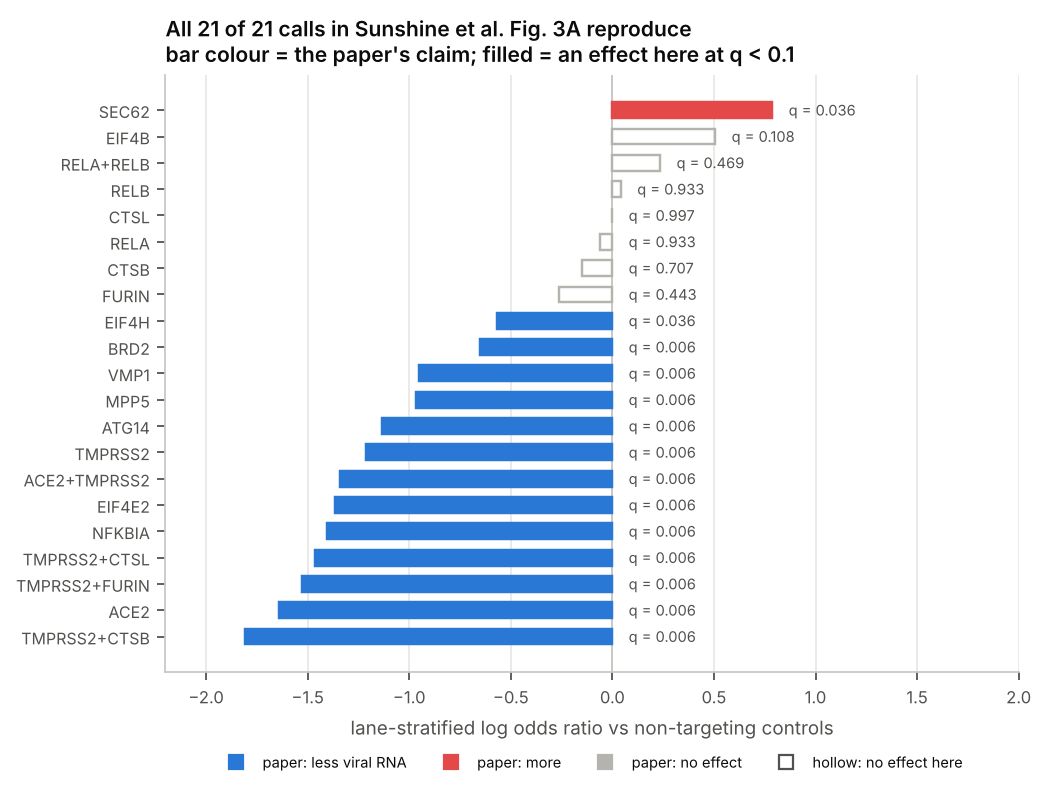

In [13]:
con = M.table("03_concordance.tsv")
con = con.sort_values("infection_log_or")
y = np.arange(len(con))
colors = [BLUE if d == "down" else RED if d == "up" else NEUTRAL
          for d in con.paper_direction]

# Fill carries this analysis's call, colour carries the paper's claim:
#   solid bar  = an effect at q < 0.1 here
#   hollow bar = no effect here
# So a hollow grey bar, however long, is a target called null both in the
# paper and here: bar length alone is not a claim.
called = (con.infection_q < 0.1).to_numpy()

fig, ax = plt.subplots(figsize=(6.6, 5.2))
ax.axvline(0, color="#c9c8c3", linewidth=0.9, zorder=1)
ax.barh(y, con.infection_log_or,
        color=[c if k else "none" for c, k in zip(colors, called)],
        edgecolor=colors, linewidth=1.1, height=0.6, zorder=2)
for i, (_, r) in enumerate(con.iterrows()):
    xpos = max(r.infection_log_or, 0) + 0.08
    ax.text(xpos, i, f"q = {r.infection_q:.3f}", va="center", ha="left",
            fontsize=6.6, color=INK2)
ax.set_yticks(y)
ax.set_yticklabels(con.target, fontsize=7.2)
style(ax, grid_axis="x")
ax.set_xlabel("lane-stratified log odds ratio vs non-targeting controls")
ax.set_xlim(-2.2, 2.0)
n_ok = int(con.agrees.sum())
ax.set_title(
    f"All {n_ok} of {len(con)} calls in Sunshine et al. Fig. 3A reproduce\n"
    "bar colour = the paper's claim; filled = an effect here at q < 0.1",
    loc="left", fontsize=9.5,
)
ax.legend(handles=[
    Line2D([], [], marker="s", color=BLUE, linestyle="", markersize=6,
           label="paper: less viral RNA"),
    Line2D([], [], marker="s", color=RED, linestyle="", markersize=6,
           label="paper: more"),
    Line2D([], [], marker="s", color=NEUTRAL, linestyle="", markersize=6,
           label="paper: no effect"),
    Line2D([], [], marker="s", markerfacecolor="none", markeredgecolor=INK2,
           color=INK2, linestyle="", markersize=6,
           label="hollow: no effect here"),
], loc="upper center", bbox_to_anchor=(0.5, -0.115), ncol=4, fontsize=6.6,
   frameon=False)
fig.tight_layout(rect=(0, 0.03, 1, 1))
fig.savefig(M.FIGURES / "concordance.png")
plt.show()

Bar colour is the paper's claim, fill is the call here. Every published call
comes back in the right direction.

## Figure: hit calling for establishment

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


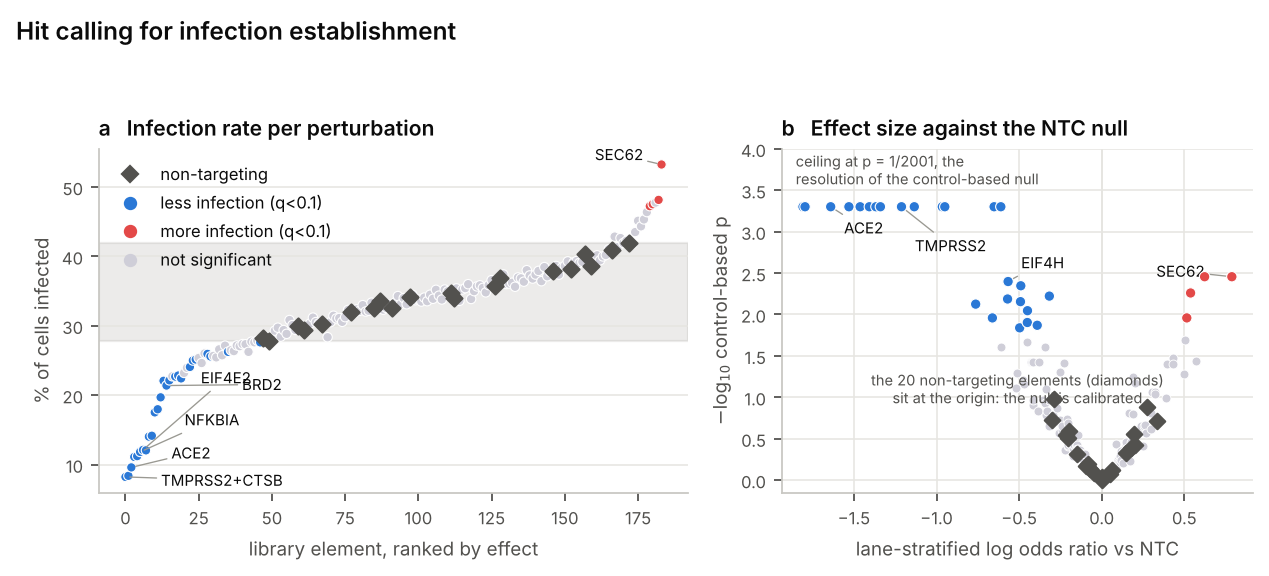

In [14]:
A = M.table("03_hits_infection.tsv")
A = A.sort_values("log_or_mh").reset_index(drop=True)
sig = (A.q_null < 0.1) & (~A.is_ntc)

fig, axes = plt.subplots(1, 2, figsize=(7.9, 3.6),
                         gridspec_kw={"width_ratios": [1.25, 1]})

# (a) the ranked panel, the analogue of the paper's Fig 3A
ax = axes[0]
x = np.arange(len(A))
ntc_band = A.loc[A.is_ntc, "infected_frac"]
ax.axhspan(ntc_band.min() * 100, ntc_band.max() * 100, color=NEUTRAL,
           alpha=0.25, zorder=0)
colors = np.where(A.is_ntc, NEUTRAL, np.where(sig, np.where(A.log_or_mh < 0, BLUE, RED), "#cfced8"))
ax.scatter(x, A.infected_frac * 100, s=18, c=colors, edgecolor="white",
           linewidth=0.5, zorder=3)
ax.scatter(x[A.is_ntc.to_numpy()], A.loc[A.is_ntc, "infected_frac"] * 100,
           s=26, color=INK2, marker="D", zorder=4, label="non-targeting")
label_offsets = {
    "TMPRSS2+CTSB": (16, -4), "ACE2": (18, 4), "NFKBIA": (20, 12),
    "EIF4E2": (26, 30), "BRD2": (34, -2), "SEC62": (-30, 2),
}
for tgt, off in label_offsets.items():
    row = A[A.target == tgt]
    if len(row):
        i = int(row.index[0])
        ax.annotate(tgt, (i, row.infected_frac.iloc[0] * 100),
                    textcoords="offset points", xytext=off, fontsize=6.8, color=INK,
                    arrowprops=dict(arrowstyle="-", color="#9a9992", lw=0.6,
                                    shrinkA=0, shrinkB=2))
style(ax)
ax.set_xlabel("library element, ranked by effect")
ax.set_ylabel("% of cells infected")
ax.set_title("a   Infection rate per perturbation", loc="left")
ax.legend(handles=[
    Line2D([], [], marker="D", color=INK2, linestyle="", markersize=5, label="non-targeting"),
    Line2D([], [], marker="o", color=BLUE, linestyle="", markersize=5, label="less infection (q<0.1)"),
    Line2D([], [], marker="o", color=RED, linestyle="", markersize=5, label="more infection (q<0.1)"),
    Line2D([], [], marker="o", color="#cfced8", linestyle="", markersize=5, label="not significant"),
], loc="upper left", ncol=1)

# (b) effect vs significance
ax = axes[1]
nl = -np.log10(A.p_null.clip(lower=1e-4))
ax.scatter(A.log_or_mh[~sig & ~A.is_ntc], nl[~sig & ~A.is_ntc], s=16,
           color="#cfced8", edgecolor="white", linewidth=0.4, zorder=2)
ax.scatter(A.log_or_mh[A.is_ntc], nl[A.is_ntc], s=24, color=INK2, marker="D", zorder=3)
ax.scatter(A.log_or_mh[sig], nl[sig], s=22,
           c=np.where(A.log_or_mh[sig] < 0, BLUE, RED),
           edgecolor="white", linewidth=0.5, zorder=4)
for tgt, off in {"ACE2": (6, -12), "TMPRSS2": (6, -20), "SEC62": (-34, 0),
                 "EIF4H": (6, 6)}.items():
    row = A[A.target == tgt]
    if len(row):
        ax.annotate(tgt, (row.log_or_mh.iloc[0], nl[row.index[0]]),
                    textcoords="offset points", xytext=off, fontsize=6.8, color=INK,
                    arrowprops=dict(arrowstyle="-", color="#9a9992", lw=0.6,
                                    shrinkA=0, shrinkB=2))
style(ax, grid_axis="both")
ax.axvline(0, color=GRID, linewidth=0.8)
ax.set_ylim(-0.15, 4.0)
ax.set_xlabel("lane-stratified log odds ratio vs NTC")
ax.set_ylabel("$-$log$_{10}$ control-based p")
ax.set_title("b   Effect size against the NTC null", loc="left")
ax.annotate(f"ceiling at p = 1/{B_DRAWS + 1}, the\nresolution of the control-based null",
            xy=(0.03, 0.99), xycoords="axes fraction", va="top",
            fontsize=6.6, color=INK2)
ax.annotate(f"the {int(A.is_ntc.sum())} non-targeting elements (diamonds)\nsit at the origin: the null is calibrated",
            xy=(0.5, 0.26), xycoords="axes fraction", ha="center",
            fontsize=6.6, color=INK2)

fig.suptitle("Hit calling for infection establishment",
             x=0.005, ha="left", fontsize=11, fontweight="semibold")
fig.tight_layout(rect=(0, 0, 1, 0.93))
fig.savefig(M.FIGURES / "viral_hits.png")
plt.show()

The non-targeting elements (diamonds) sit at the origin of panel b, which is the
same calibration check in picture form.